In [1]:
from configparser import Interpolation
import os 
import cv2
import numpy as np
from scipy import interpolate
os.chdir("C:\\YAPAY_ZEKA\\flowers")
path = os.getcwd()+'\\flowers\\'
folderNames = os.listdir(path)

xSample, ySample = [], []

for i, folderName in enumerate(folderNames): 
    for j, file in enumerate([f for f in os.listdir(path + folderName) if os.path.isfile(os.path.join(path + folderName, f))]):
        img = cv2.resize(cv2.imread(path + folderName + '/'+ file), (100, 100), interpolation=cv2.INTER_LINEAR)/255
        xSample.append(np.asarray(img))
        ySample.append(i)

xSample = np.array(xSample)
ySample = np.array(ySample)
print(xSample.shape)
print(ySample.shape)
print(xSample)
print(ySample)

(4317, 100, 100, 3)
(4317,)
[[[[0.53333333 0.5372549  0.5372549 ]
   [0.57254902 0.57254902 0.57254902]
   [0.58823529 0.58431373 0.58431373]
   ...
   [0.6        0.60784314 0.60784314]
   [0.59607843 0.60392157 0.60392157]
   [0.61176471 0.61176471 0.61176471]]

  [[0.5254902  0.53333333 0.53333333]
   [0.56470588 0.56862745 0.56862745]
   [0.58431373 0.57647059 0.58039216]
   ...
   [0.6        0.60784314 0.60784314]
   [0.59607843 0.60392157 0.60392157]
   [0.59607843 0.59607843 0.59607843]]

  [[0.49803922 0.51372549 0.51764706]
   [0.53333333 0.54117647 0.54509804]
   [0.56470588 0.57254902 0.57254902]
   ...
   [0.6        0.60784314 0.60784314]
   [0.59215686 0.6        0.6       ]
   [0.58431373 0.58431373 0.58431373]]

  ...

  [[0.09803922 0.18039216 0.16862745]
   [0.09411765 0.17647059 0.16470588]
   [0.09803922 0.18431373 0.17254902]
   ...
   [0.48627451 0.49019608 0.50588235]
   [0.47058824 0.4745098  0.49019608]
   [0.48627451 0.49019608 0.50588235]]

  [[0.10196078 0.

In [2]:
from sklearn.model_selection import train_test_split
XTrain, XTest, yTrain, yTest= train_test_split(xSample, ySample, test_size=0.10, random_state=0)
XTrain, XVal, yTrain, yVal= train_test_split(XTrain, yTrain, test_size=0.111, random_state=0)

print(XTrain.shape)
print(XTest.shape)
print(XVal.shape)

(3453, 100, 100, 3)
(432, 100, 100, 3)
(432, 100, 100, 3)


In [4]:
import tensorflow as tf
from tensorflow.keras import datasets,layers, models

model=models.Sequential()
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Conv2D(100,(3,3),activation='relu',input_shape=(100,100,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.BatchNormalization())
model.add(layers.Flatten())
model.add(layers.BatchNormalization())
model.add(layers.Dense(100, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(50, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(5, activation="softmax"))
model.summary()

model.compile(optimizer='rmsprop',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])
history = model.fit(XTrain, yTrain, epochs=10,
                    validation_data=(XVal, yVal))


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 98, 98, 100)       2800      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 49, 49, 100)      0         
 2D)                                                             
                                                                 
 batch_normalization_3 (Batc  (None, 49, 49, 100)      400       
 hNormalization)                                                 
                                                                 
 conv2d_3 (Conv2D)           (None, 47, 47, 100)       90100     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 23, 23, 100)      0         
 2D)                                                             
                                                      

c:\Users\adem\Documents\feyza\envs\yapayzeka2\lib\site-packages\keras\backend.py:5582: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


108/108 [==============================] - 190s 2s/step - loss: 18.1299 - accuracy: 0.3189 - val_loss: 1.9766 - val_accuracy: 0.2431
Epoch 2/10
108/108 [==============================] - 182s 2s/step - loss: 7.2185 - accuracy: 0.3267 - val_loss: 1.9925 - val_accuracy: 0.2569
Epoch 3/10
108/108 [==============================] - 203s 2s/step - loss: 3.0278 - accuracy: 0.2980 - val_loss: 1.6114 - val_accuracy: 0.1713
Epoch 4/10
108/108 [==============================] - 191s 2s/step - loss: 2.1250 - accuracy: 0.2896 - val_loss: 1.5394 - val_accuracy: 0.2708
Epoch 5/10
108/108 [==============================] - 192s 2s/step - loss: 1.8913 - accuracy: 0.3189 - val_loss: 1.5523 - val_accuracy: 0.2963
Epoch 6/10
108/108 [==============================] - 181s 2s/step - loss: 1.7455 - accuracy: 0.3235 - val_loss: 5.6624 - val_accuracy: 0.3148
Epoch 7/10
108/108 [==============================] - 187s 2s/step - loss: 1.6478 - accuracy: 0.3519 - val_loss: 1.4873 - val_accuracy: 0.2917
Epoch 8/1

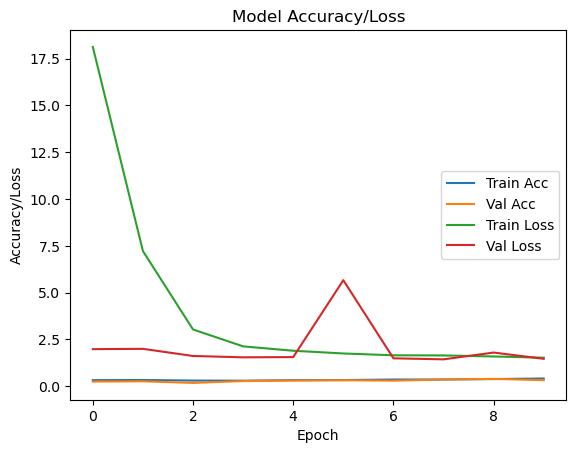

In [5]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Accuracy/Loss')
plt.ylabel('Accuracy/Loss')
plt.xlabel('Epoch')
plt.legend(['Train Acc','Val Acc', 'Train Loss', 'Val Loss'], loc='center right')
plt.show()




14/14 [==============================] - 6s 273ms/step
              precision    recall  f1-score   support

           0       0.42      0.42      0.42        81
           1       0.19      0.65      0.30        88
           2       0.38      0.04      0.08        71
           3       0.90      0.23      0.37        77
           4       0.60      0.16      0.25       115

    accuracy                           0.30       432
   macro avg       0.50      0.30      0.28       432
weighted avg       0.50      0.30      0.28       432



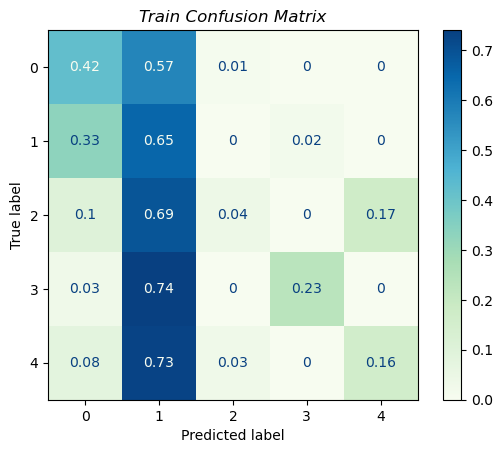

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt 
import numpy as np

yTestPred=model.predict(XTest)
yTestPred=np.argmax(yTestPred, axis=1)

print(classification_report(yTest,yTestPred))
cm=confusion_matrix(yTest,yTestPred,normalize="true").round(2)
disp=ConfusionMatrixDisplay(confusion_matrix=cm)
disp=disp.plot(cmap=plt.cm.GnBu, values_format='g')
plt.title("Train Confusion Matrix", style="italic")
plt.show()